# Classical computer vision experiment

Preview handcrafted image features and compare classical classifiers with cross-validation. The experiment focuses on LBP, HSV, HOG, and related feature combinations.


In [1]:
from pathlib import Path
import sys

notebook_dir = Path.cwd().resolve()
if not (notebook_dir / "utils.py").is_file():
    notebook_dir = notebook_dir / "notebooks"
sys.path.insert(0, str(notebook_dir))

from utils import setup_notebook_imports
setup_notebook_imports()

import importlib

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from src.experiments import classical_cv_experiment as classical_cv

importlib.reload(classical_cv)
load_data_splits = classical_cv.load_data_splits
from src.visualization import preview_handcrafted_features
from src.experiments.classical_cv_grid_search import run_compact_classical_grid

CLASS_NAMES = ["Classroom", "Library", "Cafeteria", "Parking Area", "Outdoor Campus Area"]
SPLIT_SEED = 33541943
splits = load_data_splits(seed=SPLIT_SEED, test_size=0.20)
print({name: (part["images"].shape, part["labels"].shape) for name, part in splits.items()})
print(f"Development/train: {len(splits['train']['labels'])} images ({len(splits['train']['labels']) / 627:.1%})")
print(f"Held-out test: {len(splits['test']['labels'])} images ({len(splits['test']['labels']) / 627:.1%})")
for split_name, split in splits.items():
    labels, counts = np.unique(split["labels"], return_counts=True)
    print(split_name, dict(zip(CLASS_NAMES, counts)))

{'train': ((501, 224, 224, 3), (501,)), 'test': ((126, 224, 224, 3), (126,))}
Development/train: 501 images (79.9%)
Held-out test: 126 images (20.1%)
train {'Classroom': np.int64(94), 'Library': np.int64(104), 'Cafeteria': np.int64(98), 'Parking Area': np.int64(101), 'Outdoor Campus Area': np.int64(104)}
test {'Classroom': np.int64(23), 'Library': np.int64(26), 'Cafeteria': np.int64(25), 'Parking Area': np.int64(26), 'Outdoor Campus Area': np.int64(26)}


## Preview one image's handcrafted features

The preview includes the LBP code map and normalized histogram, RGB/HSV channel distributions, HOG visualization, color means and standard deviations, and feature-vector dimensions.

c:\Users\gthra\anaconda3\envs\eel4773\Lib\site-packages\skimage\feature\texture.py:385: UserWarning: Applying `local_binary_pattern` to floating-point images may give unexpected results when small numerical differences between adjacent pixels are present. It is recommended to use this function with images of integer dtype.
  warnings.warn(


{'image_shape': (224, 224, 3), 'RGB mean': [0.5644000172615051, 0.5271000266075134, 0.48410001397132874], 'RGB standard deviation': [0.2637999951839447, 0.27239999175071716, 0.26499998569488525], 'HSV mean': [0.1615000069141388, 0.20200000703334808, 0.5702000260353088], 'HOG feature count': 26244, 'LBP histogram bins': 10, 'feature dimensions': {'hog': 26244, 'lbp': 10, 'hsv': 48}}


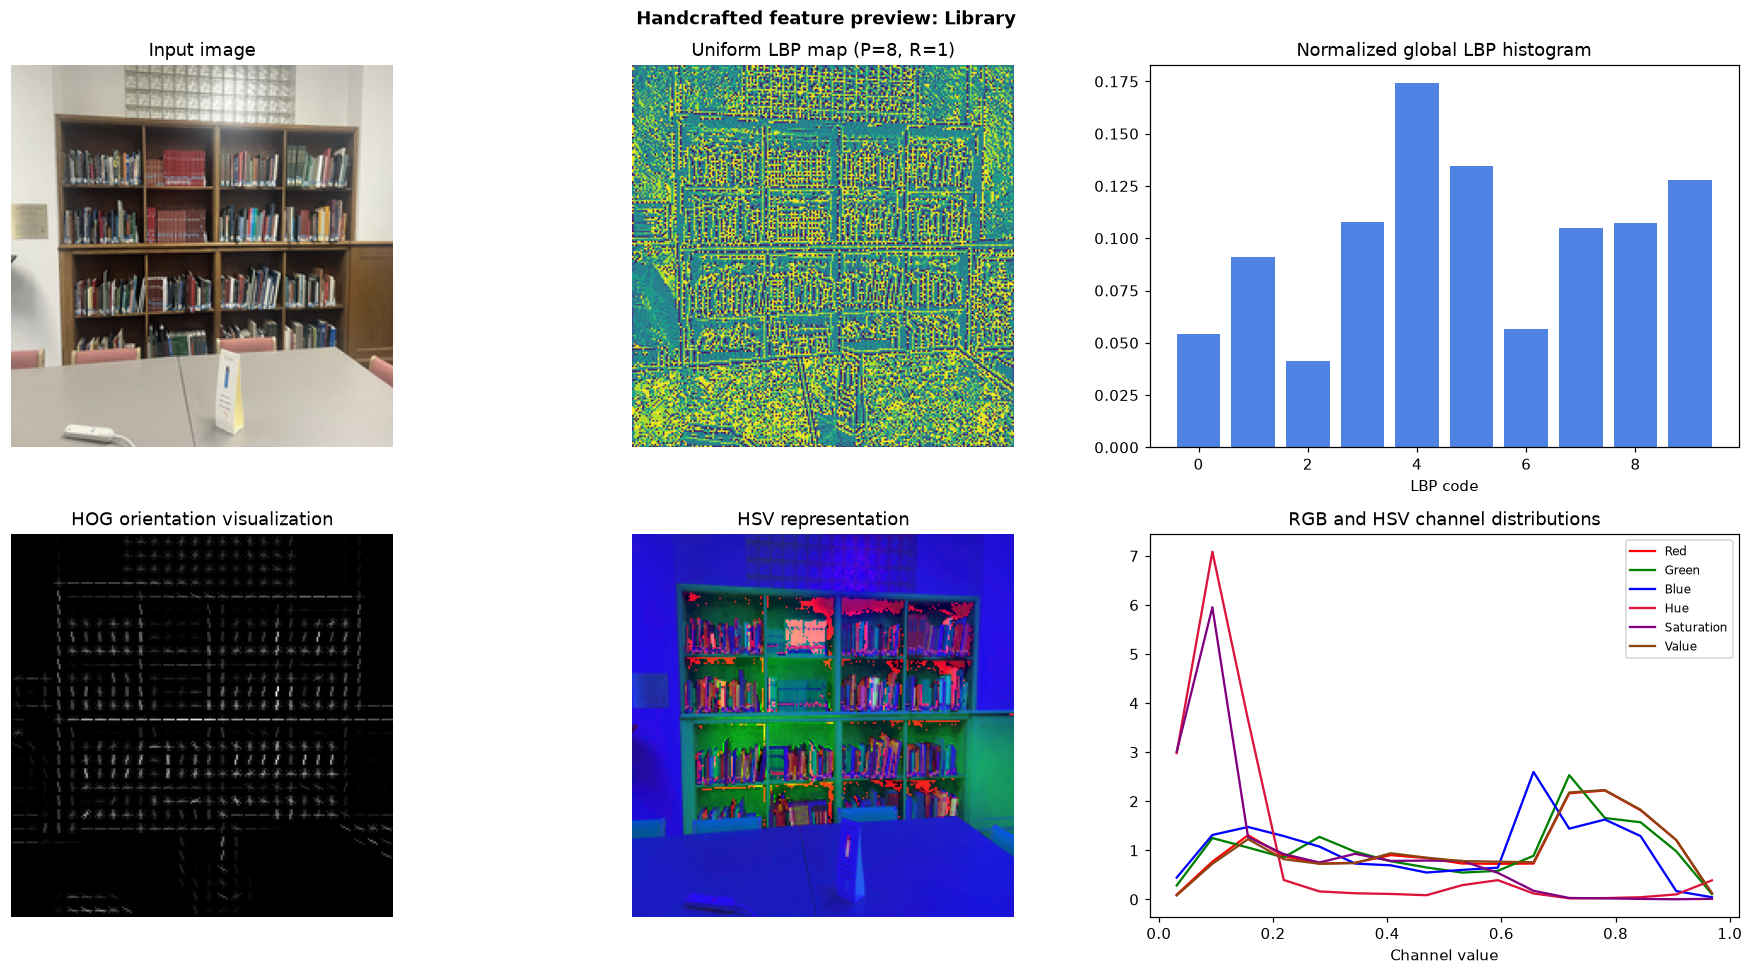

In [2]:
image_index = np.random.randint(0, len(splits["train"]["images"]))
image = splits["train"]["images"][image_index]
label = CLASS_NAMES[int(splits["train"]["labels"][image_index])]
preview_figure, preview_axes, feature_summary = preview_handcrafted_features(
    image, label=label,
    hog_orientations=9,
    hog_pixels_per_cell=(8, 8),
    lbp_points=8,
    lbp_radius=1,
    lbp_grid=(1, 1),
    color_bins=16,
);

## Compact model and feature comparison

This uses the original stratified 80/20 split seed (`33541943`) and test partition. Three-fold CV runs only inside the 80% development portion; no separate fixed validation split is made.

The grid compares five feature profiles and four classifier families. Every profile uses 0, 3, and 5 extra augmented copies: **60 candidates (180 fold fits)**. The profiles are global LBP+HSV; spatial 4x4 LBP+HSV; spatial 4x4 LBP+HSV with HOG reduced to 64 PCA components; the same spatial features with full HOG and no PCA; and spatial 4x4 LBP+HSV with Gabor features.

Classifier settings are fixed so the grid compares classifier families: RBF SVM, Random Forest, Logistic Regression, and KNN. Augmentation is generated only from each CV training fold.

In [ ]:
def run_classical_cv_grid():
    """Run the 48-candidate classical CV grid and display its ranked results."""
    search_results, best_result = run_compact_classical_grid(
        splits["train"]["images"],
        splits["train"]["labels"],
        cv_splits=3,
        seed=SPLIT_SEED,
        output_path="results/classical_cv_grid_search.csv",
    )
    results_table = pd.DataFrame([
        {key: value for key, value in row.items() if key != "model"}
        for row in search_results
    ])
    display(results_table)
    return search_results, best_result


search_results, best_result = run_classical_cv_grid()
best_model = best_result["model"]

## Final held-out test evaluation

Run this after CV selects the configuration. The test split is evaluated once and was not used for feature, augmentation, or classifier selection.

In [ ]:
test_labels = splits["test"]["labels"]
test_predictions = best_model.predict(splits["test"]["images"])
print(f"Test accuracy: {accuracy_score(test_labels, test_predictions):.3f}")
print(f"Test macro-F1: {f1_score(test_labels, test_predictions, average='macro'):.3f}")
print("Confusion matrix (true rows, predicted columns):")
print(confusion_matrix(test_labels, test_predictions))
display(pd.DataFrame(classification_report(
    test_labels, test_predictions, labels=[0, 1, 2, 3, 4],
    target_names=CLASS_NAMES, output_dict=True,
)).T)